# TP4 — Classificação de conteúdo de segurança

**Fintech Guard | Integrante A — Dados e IA | Experimento: tp4-security-binary-v1**

Pergunta: dado um texto, seu conteúdo corresponde a **benign** (benigno) ou **threat** (ameaça),
segundo os rótulos do dataset? Esta escolha segue o planejamento do TP3. Não é uma classificação
das 77 intenções bancárias e não prova intenção maliciosa de quem enviou a mensagem.
Um cliente pode relatar um golpe legitimamente.

O TP2 não rejeitou a igualdade de distribuições de comprimento entre Phishing e benigno
(Mann–Whitney, p≈0,1912); comprimento isolado não fundamenta uma regra confiável. Aqui exploramos
informação lexical com TF-IDF, sem usar códigos de classe ou comprimentos como alvo.

Este notebook executa preparo, divisão, baseline, treinamento, GridSearchCV, avaliação e
serialização. A integração HTTP e a conversa real do agente têm evidências separadas;
não são demonstradas por esta execução.

## Papel deste notebook na arquitetura do TP4

Este experimento permanece como **componente ativo de segurança**, preservando a
pergunta, o treinamento e os resultados do recorte benigno/ameaça planejado no TP3.
O [notebook BANKING77](../banking77/01_classificacao_intencoes.ipynb) acrescenta a
classificação principal das 77 intenções de atendimento bancário. Os datasets e
seus rótulos não são misturados.

`ClassificationService` reúne a intenção bancária no nível principal e este
resultado no objeto `security`, com probabilidades e versões separadas. O
[adendo](../../../reports/TP4/arquitetura_dupla.md) e o
[contrato](../../../reports/TP4/contrato_classify.md) detalham a composição.
API integrada e conversa real do agente permanecem pendentes; este notebook não
substitui essas evidências.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "scripts/tp4_classification.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from scripts.tp4_classification import (prepare, SEED, PARAM_GRID, LABELS,
                                       train_baselines, export_evaluation)
sns.set_theme(style="whitegrid")
FIGURES = ROOT / "reports/TP4/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Raiz do projeto identificada; execução com caminhos relativos.")

Raiz do projeto identificada; execução com caminhos relativos.


## 1. Dados e protocolo anterior ao treinamento

Reutilizamos as **603 mensagens tratadas** do TP3, preservando texto e seis categorias originais.
`NOT-Malicious General Class` vira `benign`; Baiting, Malware, Phishing, Pretexting e Scareware
viram `threat`. O script valida o SHA-256 do CSV; nenhuma linha é excluída ou reanotada.

Antes dos resultados: seed 42; aproximadamente 20% para teste; cinco folds de validação no
treino (seed 43); macro-F1 para seleção; limiar de probabilidade 0,5, com empate para benigno,
como no `predict` do classificador. Nenhum limiar operacional foi otimizado.

A auditoria exata não encontrou duplicatas normalizadas. Para reduzir sobreposição de templates,
usamos NFKC, casefold, espaços e substituição de números/URLs/emails **apenas para agrupamento**.
Textos de template idêntico ou Jaccard de conjuntos de 5-gramas de caracteres ≥0,85 (ambos ≥80
caracteres) formam componentes conexos. Essa regra é fixada antes dos modelos, não usa rótulos
e não garante independência por autor ou origem.

`StratifiedGroupKFold` mantém cada grupo inteiro em treino ou teste e em cada fold. A divisão
externa procura preservar as seis categorias; a CV usa o alvo binário. O manifesto e o protocolo
são persistidos **antes de ajustar modelos**. Uma reexecução deve produzir a mesma divisão.
A partição pedagógica da regressão do TP3 não é tratada como teste intocado.

In [2]:
df, manifest, train, test, cv = prepare(ROOT)
print("Dimensões originais:", df[["text", "category"]].shape)
display(df[["text", "category"]].dtypes.to_frame("tipo"))
display(df[["text", "category"]].isna().sum().to_frame("ausentes"))
# Evita expor textos completos na tabela descritiva; frequência e distribuição ficam abaixo.
display(df.assign(n_characters=df.text.str.len())[["category", "label", "n_characters"]].describe(include="all"))
display(pd.crosstab(manifest.category, manifest.split, margins=True))
display(pd.crosstab(manifest.label, manifest.split, margins=True))
group_audit = json.loads((ROOT / "reports/TP4/classification/group_audit.json").read_text(encoding="utf-8"))
display(pd.Series(group_audit, name="auditoria de grupos").to_frame())

Dimensões originais: (603, 2)


,tipo
text,object
category,object


,ausentes
text,0
category,0


,category,label,n_characters
count,603,603,603.000000
unique,6,2,NaN
top,NOT-Malicious General Class,threat,NaN
freq,171,432,NaN
mean,NaN,NaN,188.069652
std,NaN,NaN,400.928435
min,NaN,NaN,10.000000
25%,NaN,NaN,84.000000
50%,NaN,NaN,101.000000
75%,NaN,NaN,134.500000


split,test,train,All
category,,,
Baiting,16,64,80
Malware,15,62,77
NOT-Malicious General Class,34,137,171
Phishing,22,88,110
Pretexting,13,52,65
Scareware,20,80,100
All,120,483,603


split,test,train,All
label,,,
benign,34,137,171
threat,86,346,432
All,120,483,603


,auditoria de grupos
groups,552
groups_with_multiple_rows,40
largest_group,5
similar_pairs,53
mixed_binary_label_groups,0
train_rows,483
test_rows,120
cross_split_groups,0
cross_cv_fold_groups,0


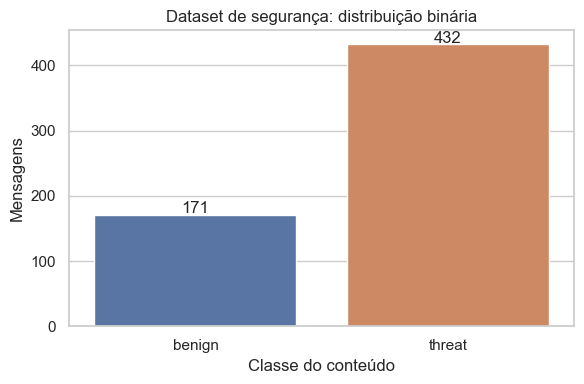

In [3]:
counts = df.label.value_counts().reindex(LABELS)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, ax=ax)
ax.set(title="Dataset de segurança: distribuição binária", xlabel="Classe do conteúdo", ylabel="Mensagens")
for i, value in enumerate(counts):
    ax.text(i, value + 3, str(value), ha="center")
fig.tight_layout()
fig.savefig(FIGURES / "distribuicao.png", dpi=160)
plt.show()

A classe ameaça reúne cinco categorias e tem 432 exemplos, contra 171 benignos. Acurácia
isolada favorece a classe majoritária; por isso usamos macro-F1 e métricas por classe.
O teste contém apenas cerca de 120 mensagens: poucos erros já mudam bastante as estimativas.
Os grupos reduzem semelhanças detectáveis, mas não corrigem vieses de coleta ou anotação.

## 2. Pré-processamento → TF-IDF → LogisticRegression

TF-IDF de palavras em unigramas/bigramas, lowercase, frequência sublinear e vocabulário limitado
a 20.000 termos. Não removemos stopwords indiscriminadamente para preservar negações. O
pré-processamento e o IDF são aprendidos **dentro do Pipeline**, só nos dados de ajuste de cada
fold. Categoria original, ID, grupo e hashes nunca são features.

A regressão logística L2 é uma opção simples para poucos exemplos e matrizes esparsas. Produz
`predict_proba`, necessário ao contrato; os scores não foram calibrados externamente. A análise
não treina SVM, comparadores de caracteres nem modelos adicionais após olhar o teste.

In [4]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True,
                              max_features=20000, lowercase=True, stop_words=None, min_df=1)),
    ("classifier", LogisticRegression(C=1.0, class_weight=None, solver="liblinear",
                                      max_iter=2000, random_state=SEED)),
])
display(pipeline)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.no

## 3. Baseline e seleção exclusivamente no treino

Baseline: `DummyClassifier(strategy="prior")` sempre prevê a classe majoritária e retorna as
proporções do treino como scores constantes. Também ajustamos uma configuração inicial, C=1,
min_df=1, sem pesos. Todos usam os mesmos cinco folds de treino.

Grade: **C ∈ {0,1; 1; 10}**, **min_df ∈ {1; 2; 3}** e class_weight ∈ {None; balanced}:
18 candidatos × 5 folds = 90 ajustes, mais o refit do escolhido em todo o treino. A ampliação
de min_df de dois para três valores atende ao enunciado do TP4 e foi definida antes da avaliação.
Empates de score seguem a ordem determinística de candidatos do GridSearchCV.

In [5]:
baselines, cv_scores = train_baselines(train, cv, pipeline)
search = GridSearchCV(pipeline, param_grid=PARAM_GRID, scoring="f1_macro",
                      cv=cv, n_jobs=1, refit=True, error_score="raise")
search.fit(train.text, train.label)
print("Candidatos avaliados:", len(search.cv_results_["params"]))
print("Melhores parâmetros:", search.best_params_)
print(f"Macro-F1 médio na seleção CV: {search.best_score_:.4f}")
display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
        .sort_values("rank_test_score").reset_index(drop=True))

Candidatos avaliados: 18
Melhores parâmetros: {'classifier__C': 10.0, 'classifier__class_weight': None, 'tfidf__min_df': 2}
Macro-F1 médio na seleção CV: 0.9925


,params,mean_test_score,std_test_score,rank_test_score
0,"{'classifier__C': 10.0, 'classifier__class_wei...",0.992494,0.006130,1
1,"{'classifier__C': 10.0, 'classifier__class_wei...",0.989957,0.009394,2
2,"{'classifier__C': 10.0, 'classifier__class_wei...",0.982222,0.012991,3
3,"{'classifier__C': 10.0, 'classifier__class_wei...",0.977581,0.014347,4
4,"{'classifier__C': 10.0, 'classifier__class_wei...",0.977581,0.014347,4
5,"{'classifier__C': 10.0, 'classifier__class_wei...",0.972764,0.018014,6
6,"{'classifier__C': 1.0, 'classifier__class_weig...",0.963267,0.036857,7
7,"{'classifier__C': 1.0, 'classifier__class_weig...",0.963048,0.040202,8
8,"{'classifier__C': 1.0, 'classifier__class_weig...",0.955056,0.028881,9
9,"{'classifier__C': 1.0, 'classifier__class_weig...",0.945019,0.037049,10


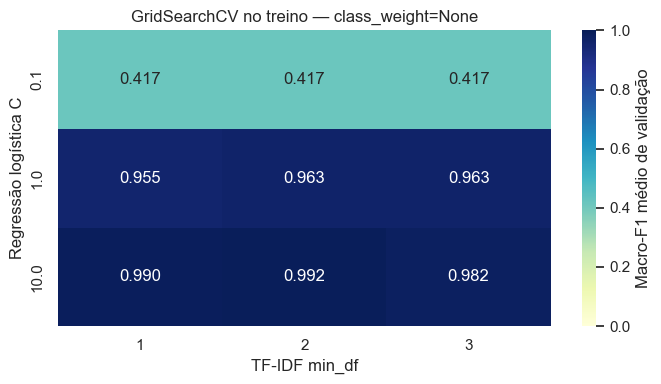

In [6]:
cv_frame = pd.DataFrame(search.cv_results_)
best_weight = search.best_params_["classifier__class_weight"]
weight_mask = cv_frame["param_classifier__class_weight"].isna() if best_weight is None else cv_frame["param_classifier__class_weight"].eq(best_weight)
grid_table = cv_frame[weight_mask].pivot(index="param_classifier__C", columns="param_tfidf__min_df", values="mean_test_score")
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(grid_table, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1,
            cbar_kws={"label": "Macro-F1 médio de validação"}, ax=ax)
ax.set(title=f"GridSearchCV no treino — class_weight={best_weight}", xlabel="TF-IDF min_df", ylabel="Regressão logística C")
fig.tight_layout()
fig.savefig(FIGURES / "grid_search.png", dpi=160)
plt.show()

O heatmap mostra somente o peso de classe selecionado, para tornar legível a comparação de C
e min_df; a tabela anterior contém os 18 candidatos. A média do vencedor é usada para seleção
e pode ser otimista por essa escolha. Ela não é desempenho externo nem resultado de teste.
O desvio padrão entre folds descreve variabilidade e não é um intervalo de confiança.

## 4. Avaliação no teste interno e serialização

Configurações e limiar estão agora fixados. A mesma partição de teste avalia baseline, modelo
inicial e escolhido; não selecionamos de novo pelo teste. O pipeline serializado mantém o
ajuste nas 483 mensagens de treino e não é reajustado nas 603 mensagens.

ROC-AUC usa `P(threat)` da coluna identificada por `classes_`, não o rótulo previsto. Average
Precision complementa a curva precisão–recall; é uma síntese por degraus, não a área trapezoidal.
Um score de 0,8 não equivale a 80% de probabilidade comprovada de fraude no mundo real.

In [7]:
metrics, details, predictions, subtype = export_evaluation(ROOT, train, test, search, baselines, cv_scores)
display(metrics.round(4))
display(pd.DataFrame(details["tuned"]["classification_report"]).T.round(4))
delta_cv = search.best_score_ - float(cv_scores["initial"].mean())
indexed = metrics.set_index("model")
delta_initial = indexed.loc["tuned", "test_macro_f1"] - indexed.loc["initial", "test_macro_f1"]
delta_dummy = indexed.loc["tuned", "test_macro_f1"] - indexed.loc["majority", "test_macro_f1"]
print(f"Ganho de macro-F1: **{delta_cv:+.4f} na seleção CV** sobre a configuração inicial; "
                 f"no teste, **{delta_initial:+.4f} sobre a inicial** e **{delta_dummy:+.4f} sobre a baseline**. "
                 "Valores negativos também são resultados válidos; não ajustamos a grade para forçar melhora.")

Ganho de macro-F1: **+0.0374 na seleção CV** sobre a configuração inicial; no teste, **+0.0426 sobre a inicial** e **+0.5825 sobre a baseline**. Valores negativos também são resultados válidos; não ajustamos a grade para forçar melhora.


,model,cv_macro_f1_mean,cv_macro_f1_std,test_macro_f1,test_accuracy,test_balanced_accuracy,test_roc_auc,test_average_precision
0,majority,0.4174,0.0014,0.4175,0.7167,0.5000,0.5,0.7167
1,initial,0.9551,0.0289,0.9574,0.9667,0.9412,1.0,1.0000
2,tuned,0.9925,0.0061,1.0000,1.0000,1.0000,1.0,1.0000


,precision,recall,f1-score,support
benign,1.0,1.0,1.0,34.0
threat,1.0,1.0,1.0,86.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,120.0
weighted avg,1.0,1.0,1.0,120.0


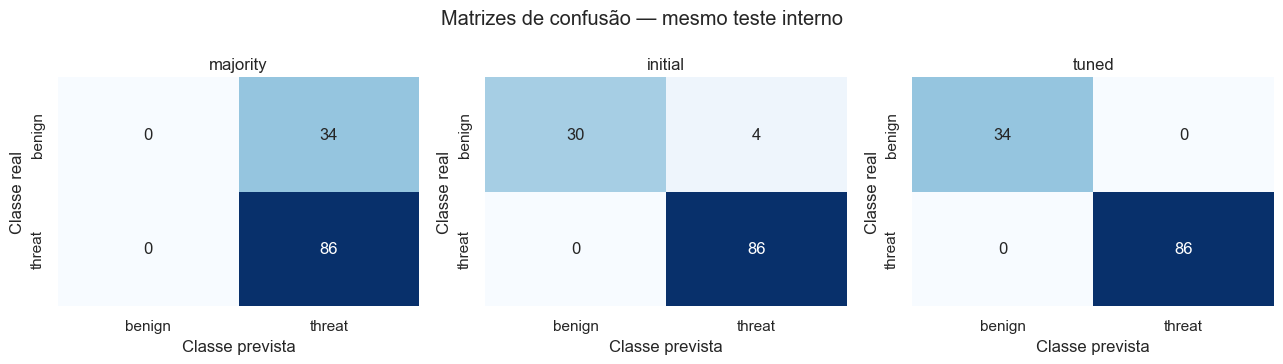

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, name in zip(axes, ["majority", "initial", "tuned"]):
    sns.heatmap(details[name]["confusion_matrix"], annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set(title=name, xlabel="Classe prevista", ylabel="Classe real")
fig.suptitle("Matrizes de confusão — mesmo teste interno")
fig.tight_layout()
fig.savefig(FIGURES / "confusao.png", dpi=160)
plt.show()

In [9]:
tn, fp, fn, tp = np.asarray(details["tuned"]["confusion_matrix"]).ravel()
print(f"No modelo selecionado: **{fn} falsos negativos** (ameaças previstas como benignas) "
                 f"e **{fp} falsos positivos** (benignos previstos como ameaça). "
                 "Falsos negativos podem deixar conteúdo suspeito passar; falsos positivos interrompem "
                 "atendimento legítimo. Os custos e o limiar operacional ainda precisam de validação "
                 "com o integrante B e dados de uso real. Esta matriz não identifica intenção pessoal.")

No modelo selecionado: **0 falsos negativos** (ameaças previstas como benignas) e **0 falsos positivos** (benignos previstos como ameaça). Falsos negativos podem deixar conteúdo suspeito passar; falsos positivos interrompem atendimento legítimo. Os custos e o limiar operacional ainda precisam de validação com o integrante B e dados de uso real. Esta matriz não identifica intenção pessoal.


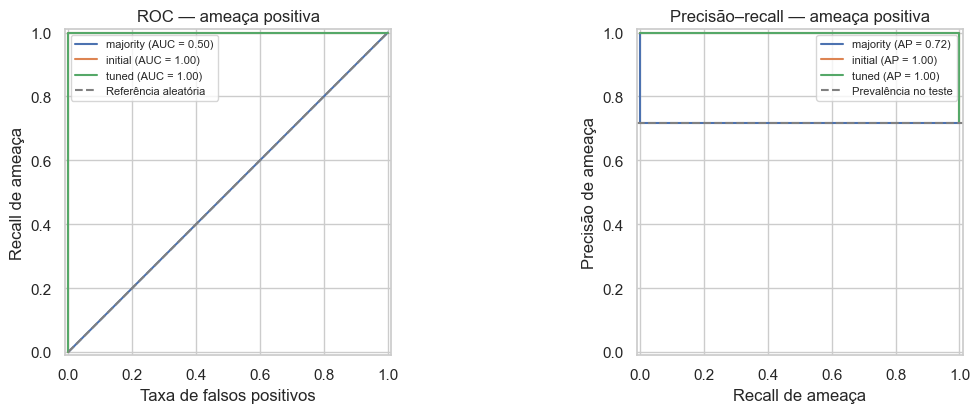

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for name in ["majority", "initial", "tuned"]:
    pred = predictions[predictions.model == name]
    truth = pred.label.eq("threat").astype(int)
    RocCurveDisplay.from_predictions(truth, pred.p_threat, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(truth, pred.p_threat, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Referência aleatória")
axes[0].set(title="ROC — ameaça positiva", xlabel="Taxa de falsos positivos", ylabel="Recall de ameaça")
axes[1].axhline(test.label.eq("threat").mean(), color="gray", linestyle="--", label="Prevalência no teste")
axes[1].set(title="Precisão–recall — ameaça positiva", xlabel="Recall de ameaça", ylabel="Precisão de ameaça")
for ax in axes:
    ax.legend(loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "roc_pr.png", dpi=160)
plt.show()

ROC-AUC resume a ordenação entre positivos e negativos em vários limiares; não mede sozinha
os erros no limiar 0,5. A curva precisão–recall deve ser lida considerando que ameaça é a classe
mais frequente (86/120 no teste). A baseline tem score constante e ROC-AUC 0,5. O desempenho
observado se refere a este teste pequeno, no mesmo domínio da coleta, não a mensagens reais em português.

## 5. Diagnóstico por subtipo original

Os rótulos de origem foram preservados para localizar erros binários. **Não treinamos um modelo
multiclasse**: esta tabela não mede a capacidade de separar Phishing de Pretexting.
Nenhum texto de teste é usado para inventar novas features, corrigir rótulos ou retreinar aqui.
O arquivo de previsões armazena IDs/hashes e scores, sem replicar mensagens brutas.

,support,errors,error_rate
original_category,,,
Baiting,16,0,0.0
Malware,15,0,0.0
NOT-Malicious General Class,34,0,0.0
Phishing,22,0,0.0
Pretexting,13,0,0.0
Scareware,20,0,0.0


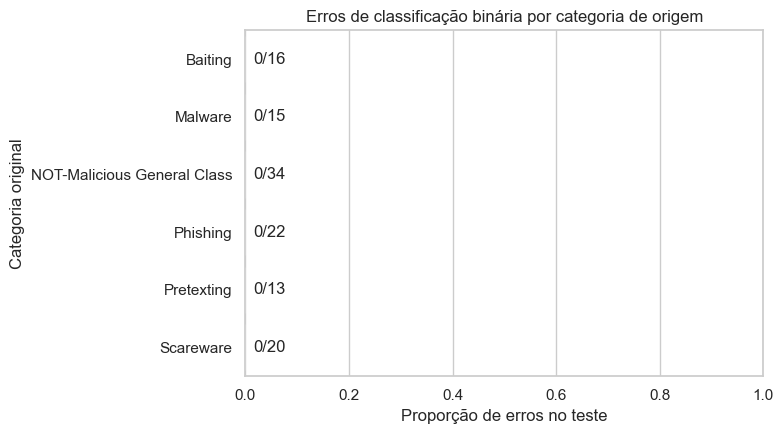

In [11]:
display(subtype)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=subtype.error_rate, y=subtype.index, hue=subtype.index, legend=False, ax=ax)
ax.set(title="Erros de classificação binária por categoria de origem", xlabel="Proporção de erros no teste", ylabel="Categoria original", xlim=(0, 1))
for i, (_, row) in enumerate(subtype.iterrows()):
    ax.text(min(row.error_rate + 0.015, .85), i, f'{int(row.errors)}/{int(row.support)}', va="center")
fig.tight_layout()
fig.savefig(FIGURES / "erros_subtipo.png", dpi=160)
plt.show()

As frações no gráfico são erros/suporte. Categorias com poucos exemplos têm estimativas instáveis;
diferenças entre barras não demonstram superioridade estatisticamente estabelecida. Uma revisão
semântica futura de Phishing/Pretexting deve usar nova amostra ou protocolo de validação próprio,
sem reaproveitar este teste para escolher o próximo modelo.

### Leitura crítica do desempenho observado

O modelo escolhido acertou os 120 exemplos deste teste interno. Isso mostra aprendizado útil
para separar os rótulos **neste corpus**, acima da baseline majoritária, mas não demonstra erro
zero no mundo real. A configuração inicial já tinha ROC-AUC 1,0 e cometeu quatro falsos positivos
no limiar 0,5; ranking correto não garante decisões perfeitas em um limiar fixo.

A revisão posterior, sem retreinar nem alterar o protocolo, conferiu IDFs com somente os 483
textos de treino: os 2.827 termos coincidem com as frequências desse subconjunto (min_df=2).
Há possíveis atalhos lexicais de coleta: download/attachment/click/password aparecem em
144/131/58/50 ameaças de treino e em nenhum benigno de treino. Esse diagnóstico é descritivo,
não prova origem sintética e não foi usado para selecionar parâmetros. A avaliação externa
em português, com relatos legítimos de golpes, é necessária antes de uso operacional.

## 6. Artefato e contrato para integração

`models/TP4/security/classifier.joblib` contém TF-IDF e classificador já ajustados. `metadata.json`
registra classes, versão, dependências, hashes, tamanho do treino, teste e limiar. O wrapper
`ml.security_classifier.SecurityClassifier` valida integridade/versões e retorna scores com
classes explícitas. Carregar uma vez na inicialização, não treinar por requisição.

O retorno interno de `SecurityClassifier` contém `task`, `label`, `probability`,
`probabilities` e `model_version`. O serviço `ClassificationService` inclui esse retorno
no objeto `security` da resposta composta, junto a `intent`, `probability` e `model_version`
do classificador BANKING77 e à tarefa `banking_intent_with_security`.

O [contrato de integração](../../../reports/TP4/contrato_classify.md) define POST `/classify`
com JWT e entrada JSON `{"text": "..."}`. O limite é de 4000 caracteres, acima do máximo 3693
observado neste dataset, sem truncamento silencioso. O `/predict` existente mantém limite
1000. Implementação do endpoint e validação HTTP com JWT permanecem pendentes de integração.

Joblib é desserialização executável: carregar somente o artefato confiável revisado. Hash verifica
integridade, não legitima origem desconhecida. O problema de licença da base ainda exige resolução.

In [12]:
from ml.security_classifier import SecurityClassifier
loaded = SecurityClassifier(ROOT / "models/TP4/security")
# Apenas valida equivalência de serialização no teste já avaliado; não é nova avaliação.
reference = predictions[predictions.model == "tuned"].set_index("row_id")
for _, row in test.iterrows():
    output = loaded.classify(row.text)
    assert output["label"] == reference.loc[row.row_id, "predicted"]
    assert np.isclose(output["probabilities"]["threat"], reference.loc[row.row_id, "p_threat"])
print(f"Artefato recarregado: {len(test)} previsões equivalentes; nenhum dado de teste usado em ajuste.")
display({key: loaded.metadata[key] for key in ["model_version", "task", "training_rows", "test_rows", "fitted_on_test", "dependencies"]})

Artefato recarregado: 120 previsões equivalentes; nenhum dado de teste usado em ajuste.


{'model_version': 'tp4-security-binary-v1',
 'task': 'security_binary',
 'training_rows': 483,
 'test_rows': 120,
 'fitted_on_test': False,
 'dependencies': {'scikit-learn': '1.9.1',
  'numpy': '2.5.4',
  'scipy': '1.18.1',
  'joblib': '1.6.0',
  'pandas': '2.2.3'}}

## 7. Limitações e próximos passos

- **Validade externa:** 603 mensagens em inglês, coleta limitada e EDA prévia sobre a base inteira.
  O teste é interno e não independente da origem; o agrupamento heurístico não elimina todo vazamento por template.
- **Taxonomia:** rótulos descrevem conteúdo e técnica de ameaça, não as intenções bancárias nem a intenção
  pessoal do remetente. Exemplos benignos que relatam golpes são um caso crítico para avaliação futura.
- **Incerteza:** apenas 34 benignos e 86 ameaças no teste; médias e diferenças não são garantias.
  A média CV selecionada é otimista e não substitui validação externa. Probabilidades não calibradas.
- **Linguagem e vocabulário:** TF-IDF lexical perde contexto, negação longa, ironia e paráfrases; palavras
  desconhecidas não acrescentam sinal. Português, dados adversariais e mudança de domínio exigem avaliação própria.
- **Direitos de uso:** licença do dataset de segurança ainda não esclarecida. Artefato acadêmico não resolve
  automaticamente permissões de produção ou redistribuição.
- **Integração:** B implementará `/classify` com JWT e controles de entrada. O agente usará esse contrato
  como apoio à triagem, sem executar transações, revelar segredos ou decidir bloqueios financeiros sozinho.
- **Agente:** chave/modelo OpenAI ainda não configurados e endpoint ainda ausente. Testes com doubles não
  valem como a conversa real de três turnos exigida. Essa evidência permanece pendente.
- **Próximos experimentos:** coletar conjunto externo bancário em português, revisar anotações de relatos
  legítimos e ambiguidade de subtipos; avaliar caracteres/SVM/calibração em treino/validação apropriados.
  Essas mudanças exigem novo protocolo de validação, sem seleção pelos resultados deste teste.

### Referências e rastreabilidade

- [Planejamento TP3](../../../reports/TP3/planejamento_T2.md)
- [Pipeline e prevenção de vazamento](https://scikit-learn.org/stable/common_pitfalls.html)
- [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)
- [Evidências TP4 e protocolo](../../../reports/TP4/README.md)

Uma reexecução idêntica é reprodução do experimento já avaliado, não um novo teste intocado.
Mudanças de hipótese/grade exigem outro registro e avaliação independente.